# Monitor de Pass-Through Cambiario e Identificación Causal
### Evaluación Descriptiva del Shock Devaluatorio de Diciembre 2023 sobre Precios Relativos
**Materia:** Programación para Economistas  
**Especialidad:** Macroeconomía, Microeconomía Aplicada e Event Study  
**Autores:** Equipo de Investigación Cuantitativa

---

## 1. Motivación Económica y Estrategia de Identificación

Ante un salto nominal en el tipo de cambio oficial, la teoría macroeconómica (*Dornbusch 1987, Burstein et al. 2005*) predice un **pass-through heterogéneo y asimétrico**:
1. **Bienes Transables:** Sujetos a arbitraje internacional (*Law of One Price*) o alto componente de insumos importados, ajustan de forma prácticamente instantánea.
2. **Bienes y Servicios No Transables:** Regulados por contratos escalonados (Calvo/Taylor) y costos laborales locales, experimentan rigideces nominales a la baja y un ajuste diferido.

Para evaluar la dinámica causal y evitar confundir el salto cambiario con la inflación general común, estimamos un modelo de **Event Study con Efectos Fijos Bidireccionales (TWFE)**:

$$\ln(P_{it}) = \alpha_i + \lambda_t + \sum_{\tau = -K, \tau \neq -1}^{L} \beta_\tau \cdot (\mathbb{I}(t - t^* = \tau) \times \text{Transable}_i) + \varepsilon_{it}$$

Donde $\tau = -1$ (Noviembre 2023) es el período base de referencia, $\alpha_i$ controla por efectos fijos de producto, $\lambda_t$ absorbe shocks macroeconómicos comunes y los errores estándar se clusterizan por producto.

## 2. Entorno: ubicación del proyecto e instalación de dependencias

La celda siguiente (a) se ubica en la raíz del proyecto o lo clona si se ejecuta en Colab, (b) instala las dependencias de `requirements.txt` (incluye `linearmodels` y `statsmodels`) y (c) fija la semilla. El análisis importa funciones desde los módulos `datos`, `econometria` e `ia` en lugar de duplicar código.

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/carolinamsfelipe/monitor-pass-through"

# (a) Ubicarse en la raíz del proyecto (o clonarlo, p. ej. en Colab)
if not os.path.isdir("datos"):
    if os.path.isdir(os.path.join("..", "datos")):
        os.chdir("..")
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "monitor-pass-through"], check=True)
        os.chdir("monitor-pass-through")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# (b) Dependencias completas (no-op si ya están instaladas)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "-r", "requirements.txt", "linearmodels", "statsmodels"],
    check=True,
)

# (c) Semilla fija y configuración
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
VENTANA = 6          # meses pre y post
FECHA_SHOCK = "2023-12-01"
USAR_LLM = False     # True: usa OPENAI_API_KEY si está definida; False: plantilla determinística

from datos.api_indec import obtener_panel_capitulos
from datos import scraping_precios as sp
from econometria.preparacion_panel import preparar_panel_event_study
from econometria.modelo_event_study import (
    estimar_event_study_twfe, extraer_tabla_coeficientes, generar_grafico_event_study,
)
from ia.auditor_econometrico import generar_dictamen, resumen_modelo

print("Proyecto:", os.path.basename(os.getcwd()))
print("Entorno inicializado correctamente.")
import matplotlib
print('Backend matplotlib:', matplotlib.get_backend())

Proyecto: mpt_work
Entorno inicializado correctamente.
Backend matplotlib: module://matplotlib_inline.backend_inline


## 3. Ingesta de Series Oficiales del IPC Nacional (INDEC)

Descarga con verificación TLS normal (sin `verify=False`) y caché local en `cache/`.

In [2]:
df_long = obtener_panel_capitulos(cache_dir="cache")
print(f"Panel cargado: {df_long['producto'].nunique()} divisiones desde {df_long['fecha'].min():%Y-%m} hasta {df_long['fecha'].max():%Y-%m}.")
df_long.head(6)

Panel cargado: 12 divisiones desde 2016-12 hasta 2026-08.


,fecha,serie_id,ipc_indice,producto,transable,justificacion
0,2016-12-01,ipc_alimentos_bebidas_no_alcoholicas_nacional,100.0000,Alimentos y Bebidas,1,Alta exposición a paridad de exportación y com...
1,2017-01-01,ipc_alimentos_bebidas_no_alcoholicas_nacional,101.3024,Alimentos y Bebidas,1,Alta exposición a paridad de exportación y com...
2,2017-02-01,ipc_alimentos_bebidas_no_alcoholicas_nacional,103.1605,Alimentos y Bebidas,1,Alta exposición a paridad de exportación y com...
3,2017-03-01,ipc_alimentos_bebidas_no_alcoholicas_nacional,106.0143,Alimentos y Bebidas,1,Alta exposición a paridad de exportación y com...
4,2017-04-01,ipc_alimentos_bebidas_no_alcoholicas_nacional,108.3515,Alimentos y Bebidas,1,Alta exposición a paridad de exportación y com...
5,2017-05-01,ipc_alimentos_bebidas_no_alcoholicas_nacional,109.7631,Alimentos y Bebidas,1,Alta exposición a paridad de exportación y com...


## 4. Construcción del Panel para el Event Study (Ventana de Evento)

In [3]:
df_panel, covars = preparar_panel_event_study(df_long, FECHA_SHOCK, VENTANA, VENTANA)
print(f"Panel con MultiIndex (producto, fecha). Dimensiones: {df_panel.shape}")
print("Covariables:", covars)

Panel con MultiIndex (producto, fecha). Dimensiones: (156, 19)
Covariables: ['treat_lead_6', 'treat_lead_5', 'treat_lead_4', 'treat_lead_3', 'treat_lead_2', 'treat_lag_0', 'treat_lag_1', 'treat_lag_2', 'treat_lag_3', 'treat_lag_4', 'treat_lag_5', 'treat_lag_6']


## 5. Estimación Econométrica TWFE y Test de Pre-tendencias

El test de Wald de pre-tendencias es una *comprobación*, no una validación: no rechazar no prueba tendencias paralelas, y con 12 clusters la inferencia es aproximada.

In [4]:
resultado, ordered_covars, wald_test = estimar_event_study_twfe(df_panel, covars)
df_coef = extraer_tabla_coeficientes(resultado, ordered_covars)
info_modelo = resumen_modelo(resultado)

print(resultado.summary)
print("\nWald pre-tendencias:", wald_test)
print("Modelo:", info_modelo)

                          PanelOLS Estimation Summary                           
Dep. Variable:             log_precio   R-squared:                        0.1015
Estimator:                   PanelOLS   R-squared (Between):             -0.0009
No. Observations:                 156   R-squared (Within):               0.0033
Date:                Sat, Oct 10 2026   R-squared (Overall):             -0.0009
Time:                        00:55:27   Log-likelihood                    187.43
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1.1293
Entities:                          12   P-value                           0.3431
Avg Obs:                       13.000   Distribution:                  F(12,120)
Min Obs:                       13.000                                           
Max Obs:                       13.000   F-statistic (robust):         -8.575e+12
                            

## 6. Gráfico de Event Study

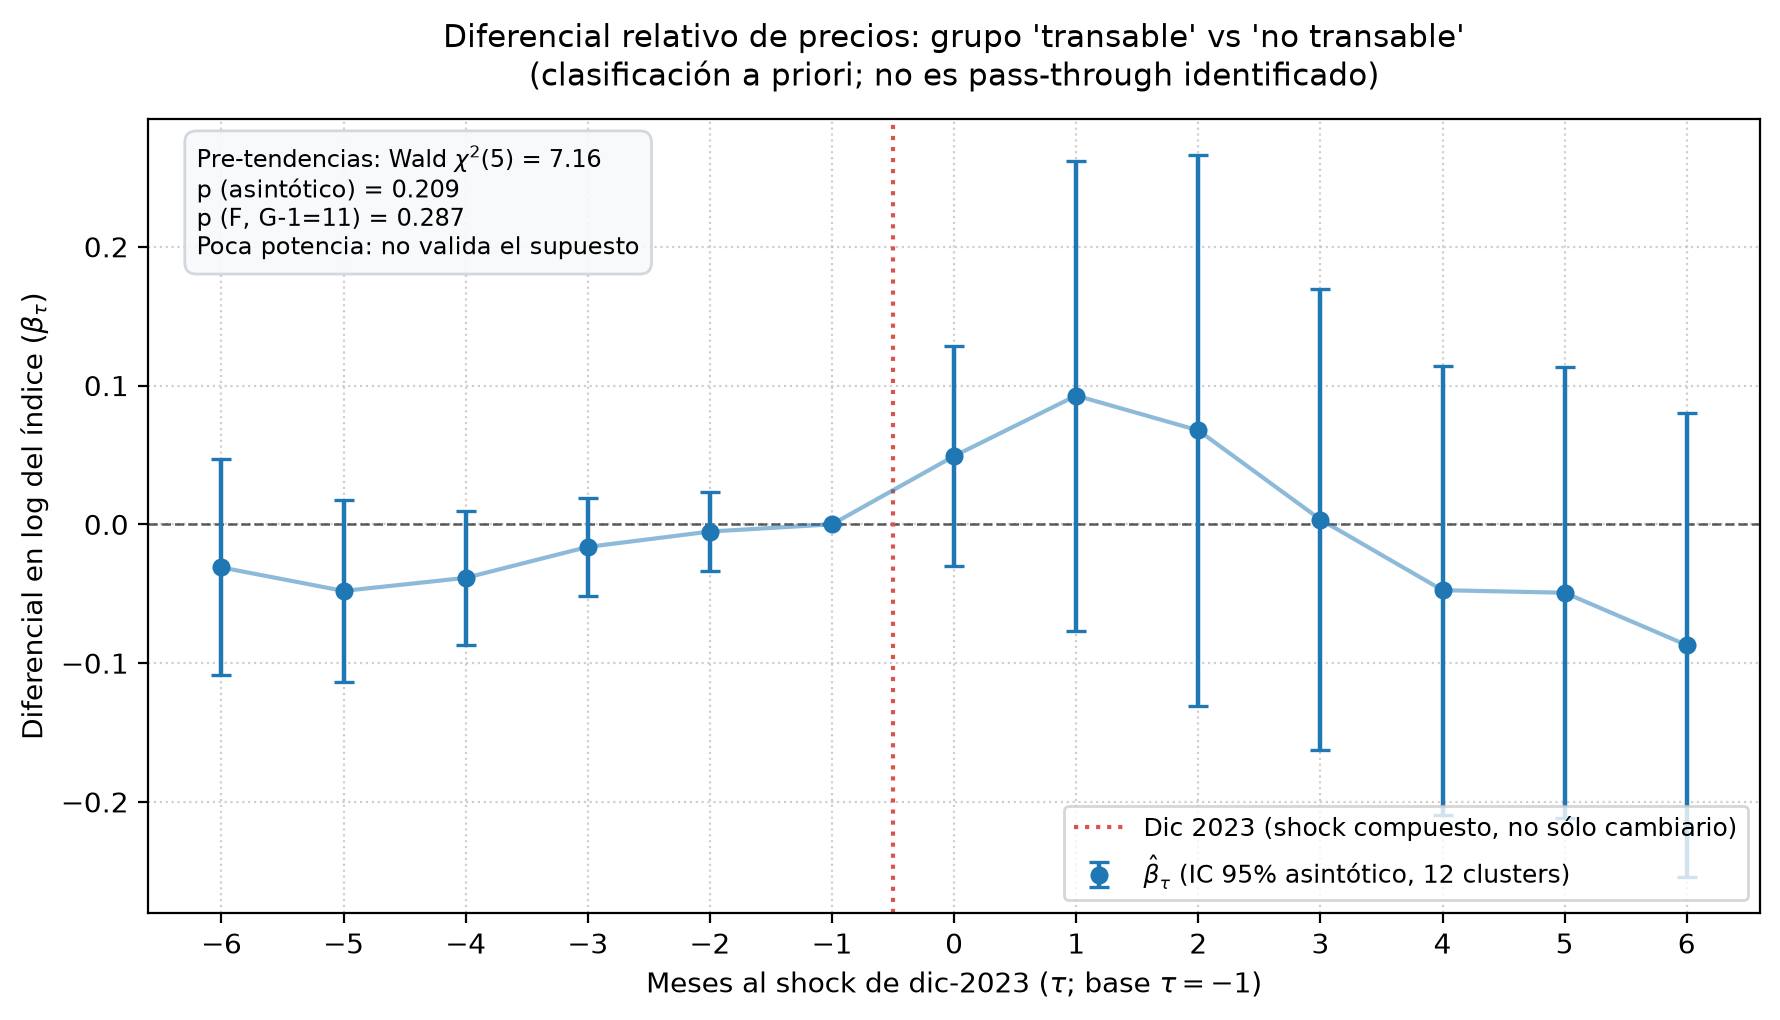

,tau,beta,std_error,pvalue,efecto_pct
0,-6,-0.031076,0.039721,0.435551,-3.059762
1,-5,-0.047993,0.033302,0.152147,-4.685945
2,-4,-0.038574,0.024740,0.121584,-3.783982
3,-3,-0.016270,0.018033,0.368739,-1.613880
4,-2,-0.005213,0.014615,0.721970,-0.519923
5,-1,0.000000,0.000000,NaN,0.000000
6,0,0.049179,0.040489,0.226893,5.040802
7,1,0.092739,0.086399,0.285253,9.717559
8,2,0.067682,0.101261,0.505166,7.002488
9,3,0.003432,0.084754,0.967771,0.343745


In [5]:
fig = generar_grafico_event_study(df_coef, wald_test)
plt.show()
df_coef[["tau", "beta", "std_error", "pvalue", "efecto_pct"]]

## 7. Góndola: canasta SIMULADA (ilustrativa)

> **DATOS SIMULADOS: esta sección no contiene precios observados.** Los valores son precios de referencia fijos más ruido aleatorio con semilla; la dispersión resultante refleja los parámetros de la simulación y no es evidencia empírica.

In [6]:
import warnings
AVISO = getattr(sp, "AVISO_SIMULACION", "DATOS SIMULADOS: no son precios observados.")
print("*" * 78); print(AVISO); print("*" * 78)

_gen = getattr(sp, "generar_canasta_simulada", None) or sp.capturar_canasta_precios
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    df_gondola = _gen()
if "fuente" not in df_gondola.columns:
    df_gondola["fuente"] = "SIMULADO"

resumen = df_gondola.groupby("categoria")["precio_ars"].agg(conteo="count", precio_promedio="mean", desvio_estandar="std")
resumen["fuente"] = "SIMULADO"
display(resumen)

******************************************************************************
DATOS SIMULADOS: los precios de góndola de esta sección NO son observaciones reales. Se generan a partir de precios de referencia fijos y ruido aleatorio con semilla; la dispersión mostrada proviene de los parámetros de simulación y no es evidencia empírica.
******************************************************************************


,conteo,precio_promedio,desvio_estandar,fuente
categoria,,,,
No Transable,6,18744.838333,16107.223227,SIMULADO
Transable,6,2193.745000,780.588157,SIMULADO


## 8. Redacción automática de resultados

El texto lo genera `ia.auditor_econometrico.generar_dictamen` a partir de los coeficientes estimados (reglas determinísticas o, opcionalmente, LLM). Es descriptivo y no establece causalidad.

In [7]:
dictamen = generar_dictamen(df_coef, wald_test, info_modelo=info_modelo, usar_llm=USAR_LLM)
print("Motor:", dictamen.motor, "| Error LLM:", dictamen.error)
display(Markdown(dictamen.texto))

Motor: plantilla | Error LLM: None


### Resultados del Event Study (shock: Diciembre 2023)

#### 1. Pre-tendencias
Test de Wald conjunto de los coeficientes pre-shock ($\tau \leq -2$; $\chi^2(5) = 7.16$, $p = 0.2091$): no se rechaza la nulidad conjunta al 5%. Esto es ausencia de evidencia en contra de tendencias previas comunes, no una validación del supuesto de tendencias paralelas (la potencia del test es limitada, en particular con pocos clusters). Con la corrección F(q, G-1) el p-valor es 0.2873. Ningún coeficiente pre-shock es individualmente significativo al 5%.

#### 2. Dinámica de los coeficientes
* **Impacto en $\tau=0$:** $\hat\beta_{0} = +0.0492$ (+5.04%; error estándar 0.0405; no significativo al 5%).
* **Mayor |coeficiente| posterior al shock ($\tau=1$):** $\hat\beta_{1} = +0.0927$ (+9.72%; error estándar 0.0864; no significativo al 5%).
* **Último período disponible ($\tau=6$):** $\hat\beta_{6} = -0.0870$ (-8.33%; error estándar 0.0852; no significativo al 5%).
* **Patrón:** los coeficientes posteriores cambian de signo; 0 de 7 son significativos al 5%.
* **Evolución:** el último coeficiente tiene signo opuesto al máximo.

#### 3. Limitaciones e interpretación
Muestra: N = 156 observaciones, 12 clusters, errores estándar clusterizados por producto. Con 12 clusters (< 30) la inferencia clusterizada asintótica puede subestimar la incertidumbre; los p-valores deben tomarse como aproximados. La clasificación transable/no transable se asigna por división del IPC y los resultados dependen de ese criterio. Los diferenciales son condicionales al diseño y no se interpretan como efectos causales. Los mecanismos económicos usuales (paridad de importación, contratos escalonados, ajuste de tarifas) son hipótesis que este diseño no contrasta.

*Texto generado automáticamente a partir de los coeficientes estimados; es descriptivo, no constituye evidencia causal y requiere revisión humana.*